#Neighborhood Graph and Clustering

In [1]:
from pathlib import Path

import anndata as ad
import scanpy as sc

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

pca_path = project_root / "data" / "interim" / "GSE176160_patients_pca.h5ad"
adata = ad.read_h5ad(pca_path)

pca_coordinates = adata.obsm["X_pca"]

assert adata.obs_names.is_unique, "Cell IDs must be unique."
assert pca_coordinates.shape == (adata.n_obs, 50), "Unexpected PCA shape."

print("Expression matrix:", adata.shape)
print("PCA coordinates:", pca_coordinates.shape)
print("Donors:", adata.obs["Donor"].nunique())
print("Lanes:", adata.obs["Lane"].nunique())

Expression matrix: (30589, 32801)
PCA coordinates: (30589, 50)
Donors: 12
Lanes: 6


In [3]:
from scipy.sparse.csgraph import connected_components

sc.pp.neighbors(
    adata,
    use_rep="X_pca",
    n_pcs=30,
    n_neighbors=15,
    metric="euclidean",
    transformer="sklearn",
    random_state=0,
)

connectivities = adata.obsp["connectivities"]
n_components = connected_components(
    connectivities,
    directed=False,
    return_labels=False,
)

print("Graph settings:", adata.uns["neighbors"]["params"])
print("Graph shape:", connectivities.shape)
print("Connected components:", n_components)

Graph settings: {'n_neighbors': 15, 'method': 'umap', 'random_state': 0, 'metric': 'euclidean', 'use_rep': 'X_pca', 'n_pcs': 30}
Graph shape: (30589, 30589)
Connected components: 1


In [7]:
sc.tl.leiden(
    adata,
    resolution=0.5,
    flavor="igraph",
    directed=False,
    use_weights=True,
    n_iterations=2,
    random_state=0,
    key_added="leiden_r05",
)

cluster_sizes = (
    adata.obs["leiden_r05"]
    .value_counts()
    .rename("n_cells")
    .to_frame()
)

assert cluster_sizes["n_cells"].sum() == adata.n_obs, "Some cells lack a cluster label."

print("Number of clusters:", len(cluster_sizes))
cluster_sizes

Number of clusters: 17


,n_cells
leiden_r05,
8,3520
10,2807
1,2498
0,2393
3,2173
4,2171
2,2125
9,1934
7,1681


In [8]:
import pandas as pd

cluster_donor_counts = pd.crosstab(
    adata.obs["leiden_r05"],
    adata.obs["Donor"],
)

cluster_cell_totals = cluster_donor_counts.sum(axis=1)

cluster_donor_summary = pd.DataFrame({
    "n_cells": cluster_cell_totals,
    "n_donors": cluster_donor_counts.gt(0).sum(axis=1),
    "top_donor": cluster_donor_counts.idxmax(axis=1),
    "top_donor_pct": (
        cluster_donor_counts.max(axis=1)
        .div(cluster_cell_totals)
        .mul(100)
    ),
}).sort_values("top_donor_pct", ascending=False)

cluster_donor_summary.round({"top_donor_pct": 2})

,n_cells,n_donors,top_donor,top_donor_pct
leiden_r05,,,,
13,1542,3,UKERiAY6-R1-003,99.55
10,2807,10,UKERiG3G-R1-039,98.50
14,1326,8,UKERi1JF-R1-018,98.49
0,2393,7,UKERi1E4-R1-003,97.16
3,2173,11,UKERiC99-R1-007,90.34
6,1438,11,UKERiJ2C-R1-015,90.33
2,2125,11,UKERiO3H-R1-005,72.80
9,1934,11,UKERiC99-R1-007,42.76
4,2171,11,UKERiC99-R1-007,40.49


In [13]:
donor_dataset_pct = adata.obs["Donor"].value_counts(normalize=True).mul(100)

cluster_donor_diagnostics = cluster_donor_summary.assign(
    top_donor_dataset_pct=(
        cluster_donor_summary["top_donor"].astype(str).map(donor_dataset_pct)
    )
)

display(cluster_donor_diagnostics.round(2))

,n_cells,n_donors,top_donor,top_donor_pct,top_donor_dataset_pct
leiden_r05,,,,,
13,1542,3,UKERiAY6-R1-003,99.55,9.76
10,2807,10,UKERiG3G-R1-039,98.50,10.58
14,1326,8,UKERi1JF-R1-018,98.49,4.56
0,2393,7,UKERi1E4-R1-003,97.16,11.27
3,2173,11,UKERiC99-R1-007,90.34,15.00
6,1438,11,UKERiJ2C-R1-015,90.33,7.10
2,2125,11,UKERiO3H-R1-005,72.80,8.98
9,1934,11,UKERiC99-R1-007,42.76,15.00
4,2171,11,UKERiC99-R1-007,40.49,15.00


In [14]:
dominant_clusters = cluster_donor_diagnostics.loc[
    cluster_donor_diagnostics["top_donor_pct"].ge(90)
]

lane_profiles = {}

for cluster_id, top_donor in dominant_clusters["top_donor"].items():
    donor_cells = adata.obs.loc[adata.obs["Donor"].eq(top_donor)]

    lane_profiles[cluster_id] = (
        donor_cells["leiden_r05"]
        .eq(cluster_id)
        .groupby(donor_cells["Lane"], observed=True)
        .mean()
        .mul(100)
    )

dominant_cluster_pct_by_lane = pd.DataFrame(lane_profiles).T
dominant_cluster_pct_by_lane.index.name = "leiden_r05"

display(dominant_cluster_pct_by_lane.round(1))

Lane,1,2,3,4,5,6
leiden_r05,,,,,,
13,51.1,52.1,51.4,50.7,52.6,50.7
10,83.5,83.9,85.2,86.4,85.8,88.4
14,95.6,90.0,95.9,96.0,92.3,92.1
0,65.7,67.1,69.0,70.8,65.4,66.4
3,42.4,41.9,46.4,40.8,41.6,43.9
6,62.1,59.9,58.6,60.4,58.6,59.6


In [15]:
sc.tl.umap(
    adata,
    min_dist=0.5,
    random_state=0,
)

print("UMAP coordinates:", adata.obsm["X_umap"].shape)

UMAP coordinates: (30589, 2)


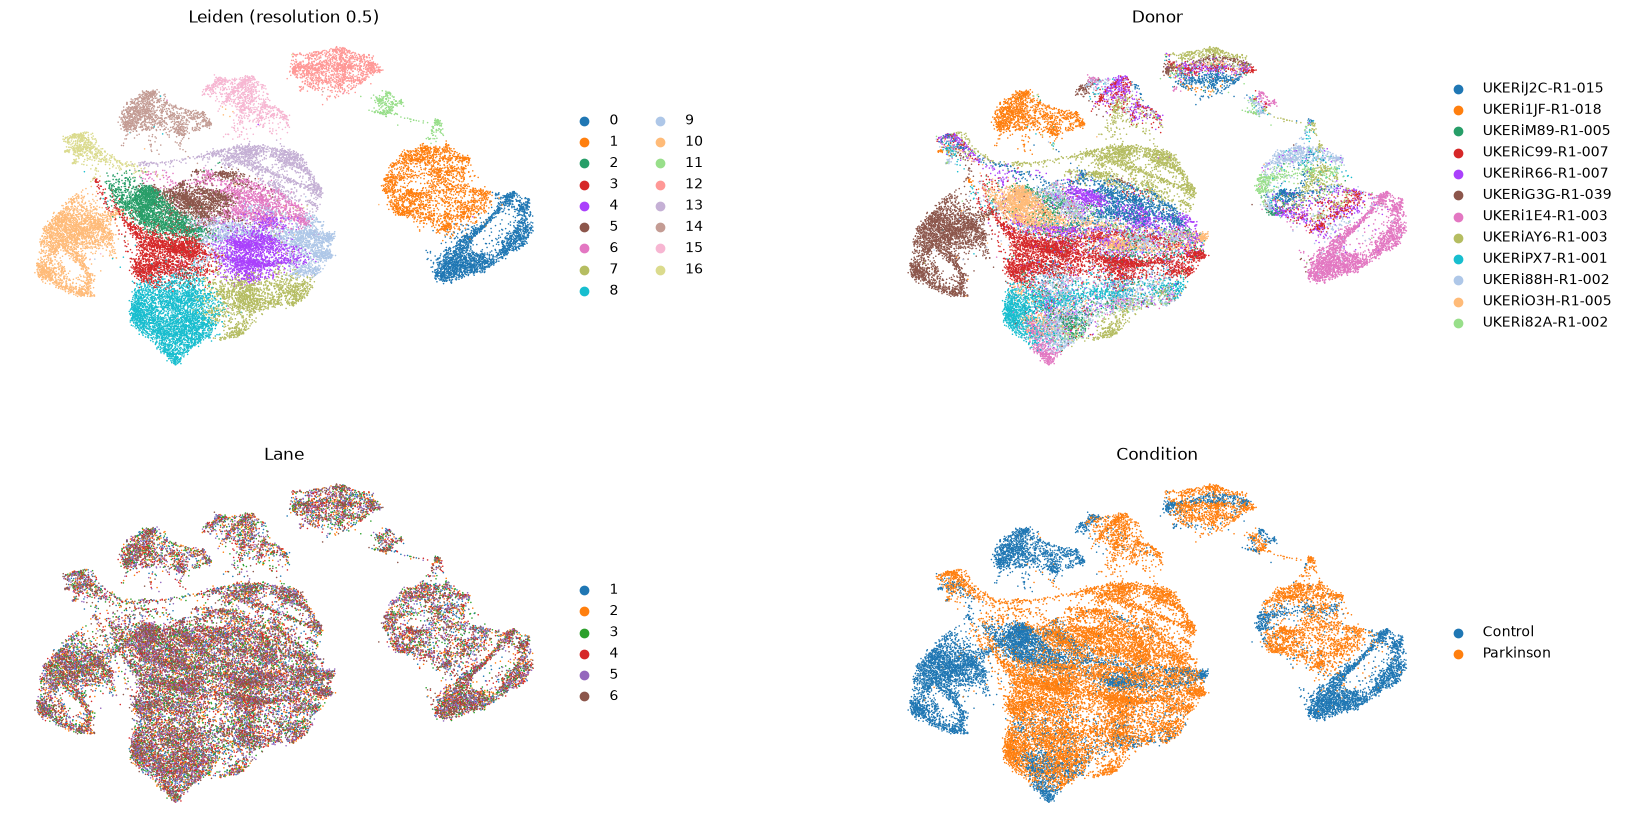

In [16]:
sc.pl.umap(
    adata,
    color=["leiden_r05", "Donor", "Lane", "condition"],
    title=["Leiden (resolution 0.5)", "Donor", "Lane", "Condition"],
    ncols=2,
    wspace=0.45,
    size=5,
    frameon=False,
)

In [17]:
for resolution, cluster_key in [(0.3, "leiden_r03"), (0.8, "leiden_r08")]:
    sc.tl.leiden(
        adata,
        resolution=resolution,
        flavor="igraph",
        directed=False,
        use_weights=True,
        n_iterations=2,
        random_state=0,
        key_added=cluster_key,
    )

for cluster_key in ["leiden_r03", "leiden_r05", "leiden_r08"]:
    sizes = adata.obs[cluster_key].value_counts()
    print(cluster_key, "| Clusters:", sizes.size, "| Smallest cluster:", sizes.min())

leiden_r03 | Clusters: 14 | Smallest cluster: 230
leiden_r05 | Clusters: 17 | Smallest cluster: 317
leiden_r08 | Clusters: 22 | Smallest cluster: 226


In [18]:
overlap_r05_r03 = pd.crosstab(
    adata.obs["leiden_r05"],
    adata.obs["leiden_r03"],
    normalize="index",
).mul(100)

display(overlap_r05_r03.loc[dominant_clusters.index].round(1))

leiden_r03,0,1,2,3,4,5,6,7,8,9,10,11,12,13
leiden_r05,,,,,,,,,,,,,,
13,0.0,0.1,10.0,0.3,89.6,0.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
10,0.0,0.2,0.0,0.1,0.0,0.0,99.7,0.0,0.0,0.0,0.0,0.0,0.0,0.0
14,0.0,0.0,0.0,0.0,0.0,0.0,0.2,0.0,0.0,0.0,0.0,99.8,0.0,0.0
0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.6,0.1,98.5,0.0,0.6,0.0,0.0,0.0,0.1,0.0,0.0,0.0,0.0
6,0.0,0.3,0.3,0.4,0.3,0.1,0.0,0.0,0.0,98.5,0.0,0.0,0.0,0.0


In [19]:
overlap_records = []

for comparison_key in ["leiden_r03", "leiden_r08"]:
    overlap_counts = pd.crosstab(
        adata.obs["leiden_r05"],
        adata.obs[comparison_key],
    )

    for reference_cluster in dominant_clusters.index:
        reference_counts = overlap_counts.loc[reference_cluster]
        matched_cluster = reference_counts.idxmax()
        shared_cells = reference_counts.loc[matched_cluster]

        overlap_records.append({
            "reference_cluster": reference_cluster,
            "comparison": comparison_key,
            "matched_cluster": matched_cluster,
            "pct_of_reference_cluster": (
                100 * shared_cells / reference_counts.sum()
            ),
            "pct_of_matched_cluster": (
                100 * shared_cells / overlap_counts[matched_cluster].sum()
            ),
        })

cluster_overlap_summary = pd.DataFrame(overlap_records)
display(cluster_overlap_summary.round(1))

,reference_cluster,comparison,matched_cluster,pct_of_reference_cluster,pct_of_matched_cluster
0,13,leiden_r03,4,89.6,96.9
1,10,leiden_r03,6,99.7,99.8
2,14,leiden_r03,11,99.8,99.9
3,0,leiden_r03,0,100.0,99.9
4,3,leiden_r03,3,98.5,65.0
5,6,leiden_r03,9,98.5,96.7
6,13,leiden_r08,16,89.6,99.7
7,10,leiden_r08,8,72.9,99.9
8,14,leiden_r08,17,99.9,100.0
9,0,leiden_r08,0,65.2,99.9


In [20]:
resolution_records = []

for resolution, cluster_key in [
    (0.3, "leiden_r03"),
    (0.5, "leiden_r05"),
    (0.8, "leiden_r08"),
]:
    donor_counts = pd.crosstab(
        adata.obs[cluster_key],
        adata.obs["Donor"],
    )

    cells_per_cluster = donor_counts.sum(axis=1)
    top_donor_share = donor_counts.max(axis=1).div(cells_per_cluster)
    donor_dominant = top_donor_share.ge(0.90)
    cells_in_donor_dominant_clusters = cells_per_cluster.loc[donor_dominant].sum()

    resolution_records.append({
        "resolution": resolution,
        "n_clusters": len(cells_per_cluster),
        "n_donor_dominant_clusters": int(donor_dominant.sum()),
        "n_cells_in_donor_dominant_clusters": int(cells_in_donor_dominant_clusters),
        "pct_cells_in_donor_dominant_clusters": (
            100 * cells_in_donor_dominant_clusters / adata.n_obs
        ),
    })

cluster_resolution_summary = pd.DataFrame(resolution_records).set_index("resolution")
display(cluster_resolution_summary.round(2))

,n_clusters,n_donor_dominant_clusters,n_cells_in_donor_dominant_clusters,pct_cells_in_donor_dominant_clusters
resolution,,,,
0.3,14,5,9413,30.77
0.5,17,6,11679,38.18
0.8,22,9,11695,38.23


In [21]:
tables_dir = project_root / "results" / "tables"
tables_dir.mkdir(parents=True, exist_ok=True)

cluster_donor_counts.to_csv(tables_dir / "cluster_donor_counts_r05.csv")
cluster_donor_diagnostics.to_csv(tables_dir / "cluster_donor_summary_r05.csv")
dominant_cluster_pct_by_lane.to_csv(tables_dir / "dominant_cluster_lane_profiles_r05.csv")
cluster_overlap_summary.to_csv(tables_dir / "cluster_resolution_overlap.csv", index=False)
cluster_resolution_summary.to_csv(tables_dir / "cluster_resolution_summary.csv")

print("Clustering tables saved to:", tables_dir)

Clustering tables saved to: /Volumes/Amin's SSD/PhD_Projects/pd-nsc-scrna/results/tables


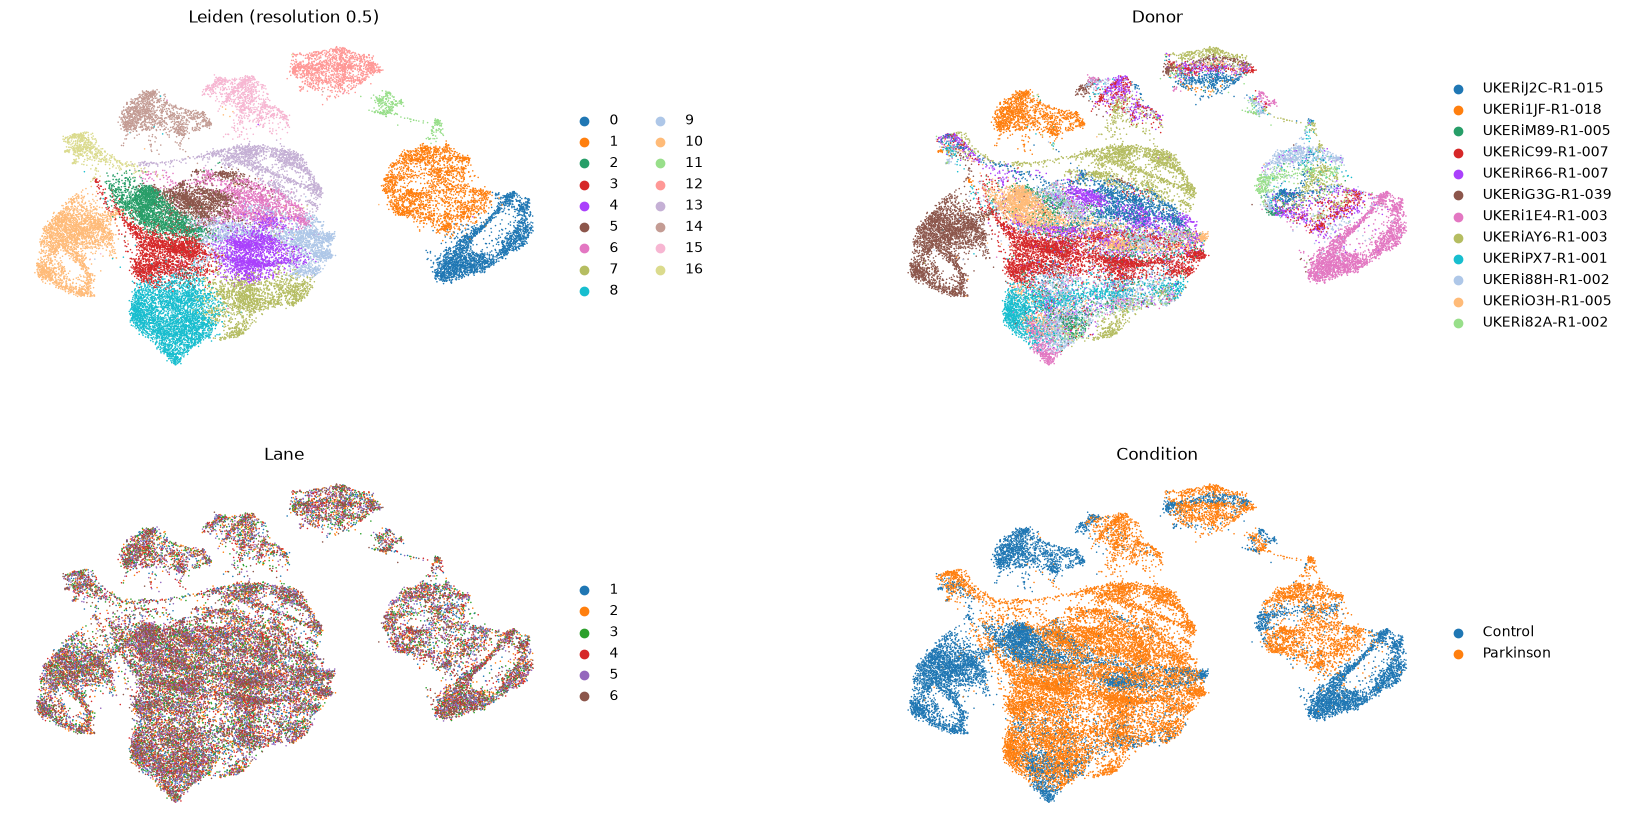

In [22]:
import matplotlib.pyplot as plt

figures_dir = project_root / "results" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

umap_figure = sc.pl.umap(
    adata,
    color=["leiden_r05", "Donor", "Lane", "condition"],
    title=["Leiden (resolution 0.5)", "Donor", "Lane", "Condition"],
    ncols=2,
    wspace=0.45,
    size=5,
    frameon=False,
    return_fig=True,
    show=False,
)

umap_figure.savefig(
    figures_dir / "umap_cluster_donor_lane_condition.png",
    dpi=300,
    bbox_inches="tight",
)
umap_figure.savefig(
    figures_dir / "umap_cluster_donor_lane_condition.pdf",
    bbox_inches="tight",
)

plt.show()

In [23]:
clustered_path = (
    project_root / "data" / "interim" / "GSE176160_patients_clustered.h5ad"
)
adata.write_h5ad(clustered_path, compression="gzip")

saved_adata = ad.read_h5ad(clustered_path, backed="r")
try:
    assert saved_adata.shape == adata.shape
    assert saved_adata.obs_names.equals(adata.obs_names)
    assert saved_adata.obsm["X_umap"].shape == (adata.n_obs, 2)

    for cluster_key in ("leiden_r03", "leiden_r05", "leiden_r08"):
        assert saved_adata.obs[cluster_key].equals(adata.obs[cluster_key])

    print("Verified expression shape:", saved_adata.shape)
    print("Verified UMAP shape:", saved_adata.obsm["X_umap"].shape)
    print("Saved clustered dataset:", clustered_path.name)
finally:
    saved_adata.file.close()

Verified expression shape: (30589, 32801)
Verified UMAP shape: (30589, 2)
Saved clustered dataset: GSE176160_patients_clustered.h5ad
